<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/EfficientNetB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("akash10rout/koa-dataset")
print("Path to dataset files:", path)

100%|██████████| 434M/434M [00:04<00:00, 101MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/akash10rout/koa-dataset/versions/1


In [2]:
!ls {path}

final_1


In [3]:
from torchvision import transforms, datasets

base = path + '/final_1'

# Fine joint-space / osteophyte detail matters for KL grading -> higher res helps.
# 300 = good trade-off on a T4. (224 = fastest, 456 = B5 native but ~2x slower than 300)
IMG_SIZE = 300

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 11226 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [4]:
# only testing
img, label = train[0]
img, label

(tensor([[[-0.5938, -0.5767, -0.5424,  ..., -0.7137, -0.7650, -0.8164],
          [-0.5938, -0.5767, -0.5596,  ..., -0.7308, -0.7822, -0.8335],
          [-0.5938, -0.5767, -0.5596,  ..., -0.7308, -0.7993, -0.8335],
          ...,
          [-1.5014, -1.5185, -1.5014,  ..., -0.7479, -0.7479, -0.7479],
          [-1.5014, -1.5185, -1.5014,  ..., -0.7308, -0.7479, -0.7479],
          [-1.5014, -1.5014, -1.5014,  ..., -0.7137, -0.7308, -0.7479]],
 
         [[-0.4776, -0.4601, -0.4251,  ..., -0.6001, -0.6527, -0.7052],
          [-0.4776, -0.4601, -0.4426,  ..., -0.6176, -0.6702, -0.7227],
          [-0.4776, -0.4601, -0.4426,  ..., -0.6176, -0.6877, -0.7227],
          ...,
          [-1.4055, -1.4230, -1.4055,  ..., -0.6352, -0.6352, -0.6352],
          [-1.4055, -1.4230, -1.4055,  ..., -0.6176, -0.6352, -0.6352],
          [-1.4055, -1.4055, -1.4055,  ..., -0.6001, -0.6176, -0.6352]],
 
         [[-0.2532, -0.2358, -0.2010,  ..., -0.3753, -0.4275, -0.4798],
          [-0.2532, -0.2358,

In [5]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

In [6]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'0': 2286, '1': 2262, '2': 2270, '3': 2228, '4': 2180}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [7]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 11226 (81.89%) | Classes: {'0': '2286 (20.4%)', '1': '2262 (20.1%)', '2': '2270 (20.2%)', '3': '2228 (19.8%)', '4': '2180 (19.4%)'}
val   | Total:  826 (6.03%) | Classes: {'0': '328 (39.7%)', '1': '153 (18.5%)', '2': '212 (25.7%)', '3': '106 (12.8%)', '4': '27 (3.3%)'}
test  | Total: 1656 (12.08%) | Classes: {'0': '639 (38.6%)', '1': '296 (17.9%)', '2': '447 (27.0%)', '3': '223 (13.5%)', '4': '51 (3.1%)'}


In [8]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.98, 0.99, 0.99, 1.01, 1.03]


In [9]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 11226


In [10]:
from torch.utils.data import DataLoader

import os
NUM_WORKERS = min(4, os.cpu_count() or 2)
BATCH_SIZE = 24   # if CUDA OOM -> 16

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([24, 3, 300, 300])
labels: tensor([1, 3, 4, 2, 0, 3, 1, 2, 0, 0])


In [11]:
import cv2
import numpy as np
from PIL import Image

# 1) دالة التنظيف: CLAHE لتحسين التباين (الـ Gaussian blur صار اختياري لأنه يطمس التفاصيل الدقيقة)
class Denoise:
    def __init__(self, blur=False):
        self.blur = blur
    def __call__(self, img):
        g = np.array(img.convert("L"))                                    # رمادي
        if self.blur:
            g = cv2.GaussianBlur(g, (3, 3), 0)                            # إزالة الضوضاء (اختياري)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train: augmentation أخف وبدون تكرار (rotation كانت مكررة مرتين، والـ crop قد يقص المفصل)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([24, 3, 300, 300])
train: 11226 | val: 826 | test: 1656


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

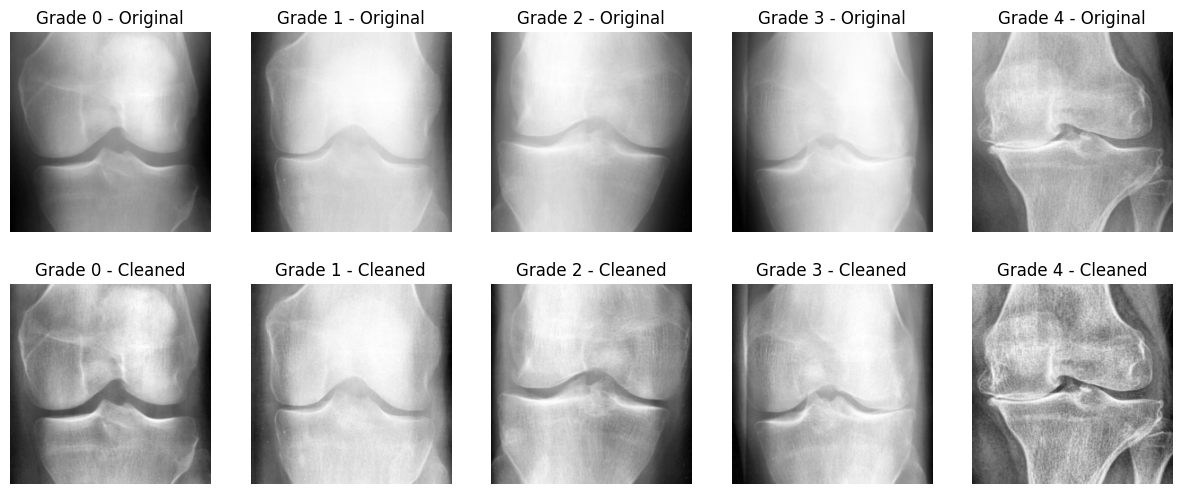

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

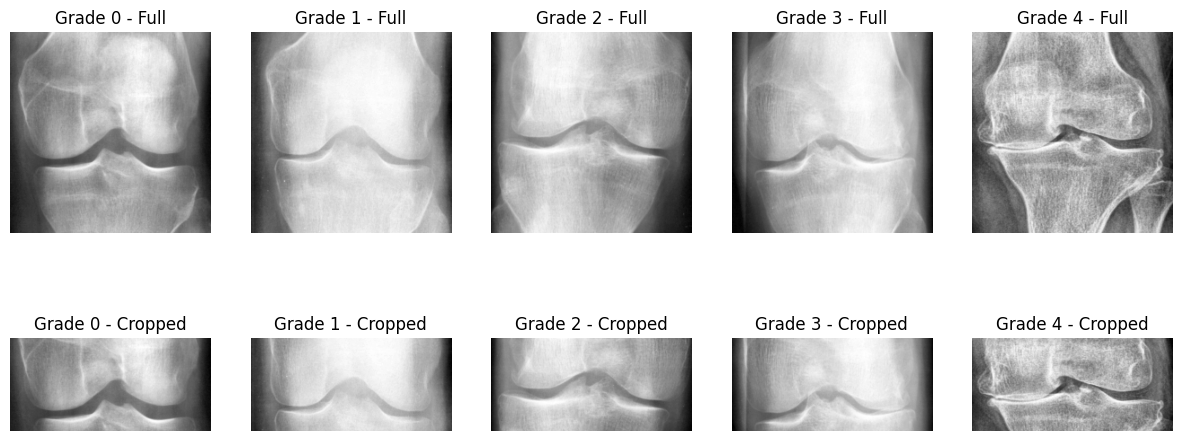

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cropped"); axes[1][k].axis("off")
plt.show()


# Agnostic Code

In [14]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (EfficientNet-B5)

## Training

In [15]:
def train_step(model,
               data_loader,
               loss_fn,
               optm,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item() * input.size(0)
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optm.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optm.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [16]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [17]:
from sklearn.metrics import f1_score

def val_macro_f1():
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in val_loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    return f1_score(labels, preds, average="macro")

In [18]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [19]:
from sklearn.metrics import f1_score

# Mixed precision (AMP) -> less GPU memory + much faster on T4
use_amp = (device == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(loader, optimizer=None, freeze_backbone=False):
    """Train one epoch if optimizer is given, otherwise just evaluate.
    Returns (loss, acc%, macro-F1) - F1 is computed in the SAME pass (no 2nd val pass)."""
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()              # keep frozen part fully fixed (like Keras)

    total_loss, correct, n = 0.0, 0, 0
    all_p, all_y = [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            pred = out.argmax(1)
            total_loss += loss.item() * len(y)
            correct += (pred == y).sum().item()
            n += len(y)
            if not training:
                all_p.append(pred.cpu()); all_y.append(y.cpu())
    f1 = f1_score(torch.cat(all_y), torch.cat(all_p), average="macro") if not training else float('nan')
    return total_loss / n, 100 * correct / n, f1


In [20]:
def test_report():
    te_loss, te_acc, _ = run_epoch(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}%")
    model.eval()
    preds, labels = [], []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
        for x, y in test_loader:
            x = x.to(device, memory_format=torch.channels_last)
            preds.extend(model(x).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    print(classification_report(labels, preds, zero_division=0))
    print(confusion_matrix(labels, preds))


In [21]:
import copy

def fit(optimizer, epochs, freeze_backbone, name, scheduler=None, patience=None):
    best_score, best_state, bad = 0, None, 0

    for e in range(epochs):
        tr_loss, tr_acc, _ = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc, f1 = run_epoch(val_loader)      # one val pass gives loss, acc and F1
        if scheduler is not None:
            scheduler.step()

        if best_state is None or f1 > best_score:
            best_score, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val F1 {f1:.3f}")

        if patience is not None and bad >= patience:
            print(f"Early stopping (no val-F1 improvement for {patience} epochs)")
            break

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val F1 {best_score:.3f})")


## PHASE 1 -- freeze EfficientNet-B5, train only the new layer, 5 epochs

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the pre-trained EfficientNet-B5 model
model = models.efficientnet_b5(weights=models.EfficientNet_B5_Weights.DEFAULT)

# 2. Freeze all backbone parameters first
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the final Linear layer (classifier = Dropout -> Linear).
#    Newly created layers have requires_grad=True by default.
num_ftrs = model.classifier[1].in_features      # 2048
model.classifier[1] = nn.Linear(num_ftrs, 5)
model = model.to(device, memory_format=torch.channels_last)

# 4. Setup loss function and optimizer
# Pass only the classifier parameters to the optimizer for Phase 1
loss_fn = nn.CrossEntropyLoss(weight=class_weights.float().to(device), label_smoothing=0.1)
optm = optim.Adam(model.classifier.parameters(), lr=0.001)

acc_fn = accuracy_fn

# Run training Phase 1
fit(optm, epochs=5, freeze_backbone=True, name="Phase 1: frozen")

print("\n--- Test result after Phase 1 ---")
test_report()


Downloading: "https://download.pytorch.org/models/efficientnet_b5_lukemelas-1a07897c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b5_lukemelas-1a07897c.pth


100%|██████████| 117M/117M [00:01<00:00, 83.5MB/s]


[Phase 1: frozen] Epoch 01/5 | train loss 1.358 acc 42.8 | val loss 1.273 acc 52.2 | val F1 0.473
[Phase 1: frozen] Epoch 02/5 | train loss 1.271 acc 48.7 | val loss 1.268 acc 51.0 | val F1 0.469
[Phase 1: frozen] Epoch 03/5 | train loss 1.251 acc 49.7 | val loss 1.249 acc 52.5 | val F1 0.483
[Phase 1: frozen] Epoch 04/5 | train loss 1.241 acc 50.7 | val loss 1.260 acc 51.1 | val F1 0.476
[Phase 1: frozen] Epoch 05/5 | train loss 1.228 acc 51.6 | val loss 1.298 acc 42.9 | val F1 0.451
Restored best epoch (val F1 0.483)

--- Test result after Phase 1 ---
TEST loss 1.289 | TEST acc 50.85%
              precision    recall  f1-score   support

           0       0.54      0.81      0.65       639
           1       0.30      0.11      0.16       296
           2       0.48      0.41      0.44       447
           3       0.46      0.32      0.38       223
           4       0.70      0.69      0.69        51

    accuracy                           0.51      1656
   macro avg       0.50   

## PHASE 2 -- unfreeze everything: AdamW, lower LR for backbone, warmup + cosine schedule, early stopping

In [23]:
for p in model.parameters():
    p.requires_grad = True

EPOCHS2 = 30

# NEW optimizer: small LR for the pretrained backbone, bigger LR for the new head
optm = optim.AdamW([
    {"params": model.features.parameters(),   "lr": 5e-5},
    {"params": model.classifier.parameters(), "lr": 5e-4},
], weight_decay=1e-2)

# 2 epochs warmup, then cosine decay
warm  = optim.lr_scheduler.LinearLR(optm, start_factor=0.1, total_iters=2)
cos   = optim.lr_scheduler.CosineAnnealingLR(optm, T_max=EPOCHS2 - 2, eta_min=1e-6)
sched = optim.lr_scheduler.SequentialLR(optm, [warm, cos], milestones=[2])

fit(optm, epochs=EPOCHS2, freeze_backbone=False, name="Phase 2: fine-tune",
    scheduler=sched, patience=8)

print("\n--- Final test result after fine-tuning ---")
test_report()


[Phase 2: fine-tune] Epoch 01/30 | train loss 1.464 acc 38.0 | val loss 1.366 acc 40.8 | val F1 0.391
[Phase 2: fine-tune] Epoch 02/30 | train loss 1.181 acc 55.0 | val loss 1.142 acc 58.4 | val F1 0.571
[Phase 2: fine-tune] Epoch 03/30 | train loss 1.001 acc 66.0 | val loss 1.048 acc 62.6 | val F1 0.651
[Phase 2: fine-tune] Epoch 04/30 | train loss 0.914 acc 71.1 | val loss 1.000 acc 64.6 | val F1 0.673
[Phase 2: fine-tune] Epoch 05/30 | train loss 0.861 acc 74.5 | val loss 0.945 acc 68.3 | val F1 0.708
[Phase 2: fine-tune] Epoch 06/30 | train loss 0.819 acc 76.3 | val loss 0.939 acc 70.0 | val F1 0.722
[Phase 2: fine-tune] Epoch 07/30 | train loss 0.772 acc 79.6 | val loss 0.917 acc 72.3 | val F1 0.760
[Phase 2: fine-tune] Epoch 08/30 | train loss 0.726 acc 82.3 | val loss 0.856 acc 74.0 | val F1 0.771
[Phase 2: fine-tune] Epoch 09/30 | train loss 0.690 acc 84.7 | val loss 0.841 acc 78.2 | val F1 0.804
[Phase 2: fine-tune] Epoch 10/30 | train loss 0.661 acc 86.6 | val loss 0.821 acc 

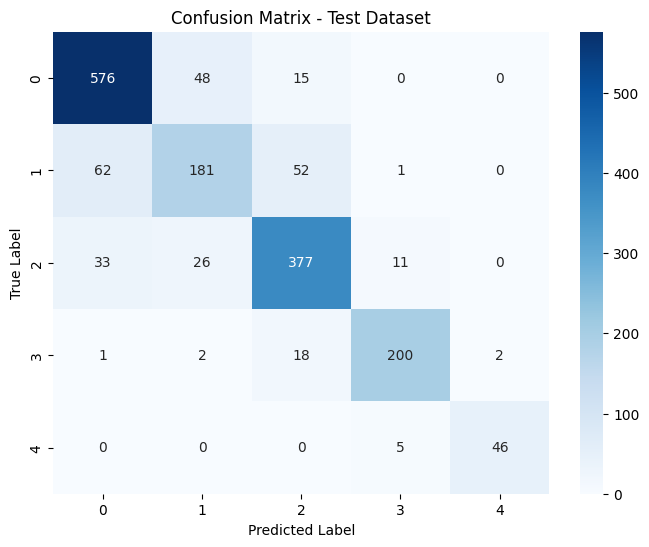

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
from sklearn.metrics import cohen_kappa_score
import torch

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on the test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Calculate Quadratic Weighted Kappa (QWK)
qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")

## Final evaluation with TTA (original + horizontal flip) and QWK

In [26]:
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix

@torch.no_grad()
def predict_probs(loader, tta=True):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device, memory_format=torch.channels_last)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)

probs, labels = predict_probs(test_loader, tta=True)
pred_argmax = probs.argmax(1)
pred_expect = (probs * torch.arange(5)).sum(1).round().long().clamp(0, 4)   # ordinal-aware rounding

for name, pr in [("argmax", pred_argmax), ("expected-grade rounding", pred_expect)]:
    acc = (pr == labels).float().mean().item() * 100
    qwk = cohen_kappa_score(labels, pr, weights='quadratic')
    print(f"{name:25s} | acc {acc:.2f}% | QWK {qwk:.4f}")

print(classification_report(labels, pred_argmax, zero_division=0))
print(confusion_matrix(labels, pred_argmax))


argmax                    | acc 83.21% | QWK 0.9048
expected-grade rounding   | acc 82.43% | QWK 0.9153
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       639
           1       0.71      0.61      0.66       296
           2       0.81      0.84      0.82       447
           3       0.92      0.90      0.91       223
           4       0.98      0.90      0.94        51

    accuracy                           0.83      1656
   macro avg       0.86      0.83      0.84      1656
weighted avg       0.83      0.83      0.83      1656

[[576  46  17   0   0]
 [ 61 180  54   1   0]
 [ 36  24 376  11   0]
 [  0   2  20 200   1]
 [  0   0   0   5  46]]
